# 01. Exploration neurophysiologique de l'imagerie motrice

**Question :** quand un sujet *imagine* bouger une main, voit-on une signature mesurable dans l'EEG,
et est-elle latéralisée ?

Tout est calculé sur la **session d'entraînement uniquement** : la session de test reste vierge
pour l'évaluation des phases suivantes. Le code de calcul est dans `src/exploration.py`,
ce notebook ne fait que l'appeler et afficher.

In [1]:
import os, sys
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RACINE); sys.path.insert(0, str(RACINE))

import mne
import pandas as pd
from IPython.display import Image, display
from src.chargement import charger_brut, fixer_graine
from src.exploration import epoquer_session, verifier_marqueurs

fixer_graine()
mne.set_log_level("ERROR")

## 1. Structure des données du sujet 1

Chaque session contient 6 runs de 48 essais (12 par classe), enregistrés sur 22 électrodes EEG
et 3 électrodes EOG à 250 Hz.

In [2]:
raw = charger_brut(1)["0train"]["0"]
print(raw)
print("Canaux EEG :", raw.copy().pick("eeg").ch_names)
print("Premières annotations :", list(zip(raw.annotations.onset[:4], raw.annotations.description[:4])))

<RawArray | 26 x 96735 (386.9 s), ~19.2 MiB, data loaded>
Canaux EEG : ['Fz', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P1', 'Pz', 'P2', 'POz']
Premières annotations : [(np.float64(3.0), 'tongue'), (np.float64(11.012), 'feet'), (np.float64(18.684), 'right_hand'), (np.float64(26.492), 'left_hand')]


## 2. Où commence la fenêtre d'imagerie ?

Déroulé officiel d'un essai : croix de fixation et bip à t = 0 s, flèche (indice) à t = 2 s,
imagerie jusqu'à t = 6 s. MOABB déclare `interval = [2, 6]`.

Piège : dans la version installée de MOABB, chaque annotation est placée **sur l'indice** (t = 2 s)
avec une durée de 4 s, et non au début de l'essai. On vérifie donc, contre le fichier `.mat`
officiel de la compétition, le décalage des marqueurs puis l'endroit où commencent réellement
les époques du paradigme (corrélation avec le signal brut à +0 s et +2 s du marqueur).

In [3]:
verification = pd.read_csv("results/phase1_verification_marqueurs.csv")
verification

,sujet,n_essais,decalage_min_s,decalage_max_s,etiquettes_identiques,duree_annotation_s,correlation_epoque_marqueur_plus_0s,correlation_epoque_marqueur_plus_2s,fenetre_paradigme_moabb
0,1,288,2.0,2.0,True,4.0,0.9959,-0.1797,"[2, 6]"
1,2,288,2.0,2.0,True,4.0,0.9742,-0.0429,"[2, 6]"
2,3,288,2.0,2.0,True,4.0,0.9890,0.0367,"[2, 6]"
3,4,288,2.0,2.0,True,4.0,0.9744,0.0408,"[2, 6]"
4,5,288,2.0,2.0,True,4.0,0.9945,-0.0053,"[2, 6]"
5,6,288,2.0,2.0,True,4.0,0.9915,-0.1831,"[2, 6]"
6,7,288,2.0,2.0,True,4.0,0.9928,-0.0630,"[2, 6]"
7,8,288,2.0,2.0,True,4.0,0.9924,-0.0839,"[2, 6]"
8,9,288,2.0,2.0,True,4.0,0.9945,-0.1712,"[2, 6]"


**Lecture :** décalage constant de +2 s (le marqueur est sur l'indice), étiquettes identiques au fichier
officiel, et l'époque du paradigme coïncide avec le signal brut au marqueur (+0 s), pas à +2 s.
La fenêtre utilisée par MOABB est donc bien [indice, indice + 4 s] = [2, 6] s en temps d'essai.
MOABB affiche simplement les temps de l'époque en « temps d'essai » (2 à 6 s).

## 3. Pourquoi un laplacien de surface ?

Les signaux sont enregistrés contre une référence commune (mastoïde gauche). Par conduction volumique,
une source puissante, comme le rythme alpha visuel à l'arrière de la tête, diffuse sur toutes
les électrodes, y compris C3 et C4, et masque l'ERD motrice locale. Le laplacien de surface
(`mne.preprocessing.compute_current_source_density`) retire à chaque électrode l'activité commune
à ses voisines et ne garde que la source située juste sous elle. Les deux dérivations sont calculées
et comparées en section 7 ; les figures principales utilisent le laplacien.

## 4. Cartes temps-fréquence (sujet 1)

ERD% = (P - R) / R x 100, avec R la puissance de repos sur [-1,5 ; -0,5] s avant l'indice.
Bleu = baisse de puissance (désynchronisation, ERD), rouge = hausse (ERS).
Les lignes blanches marquent 8, 12 et 30 Hz ; les pointillés, l'indice et la fin de l'imagerie.
La tache rouge à 4-8 Hz juste après l'indice est la réponse évoquée visuelle à la flèche, pas de l'imagerie :
c'est pourquoi la fenêtre de mesure de l'ERD commence à 0,5 s.

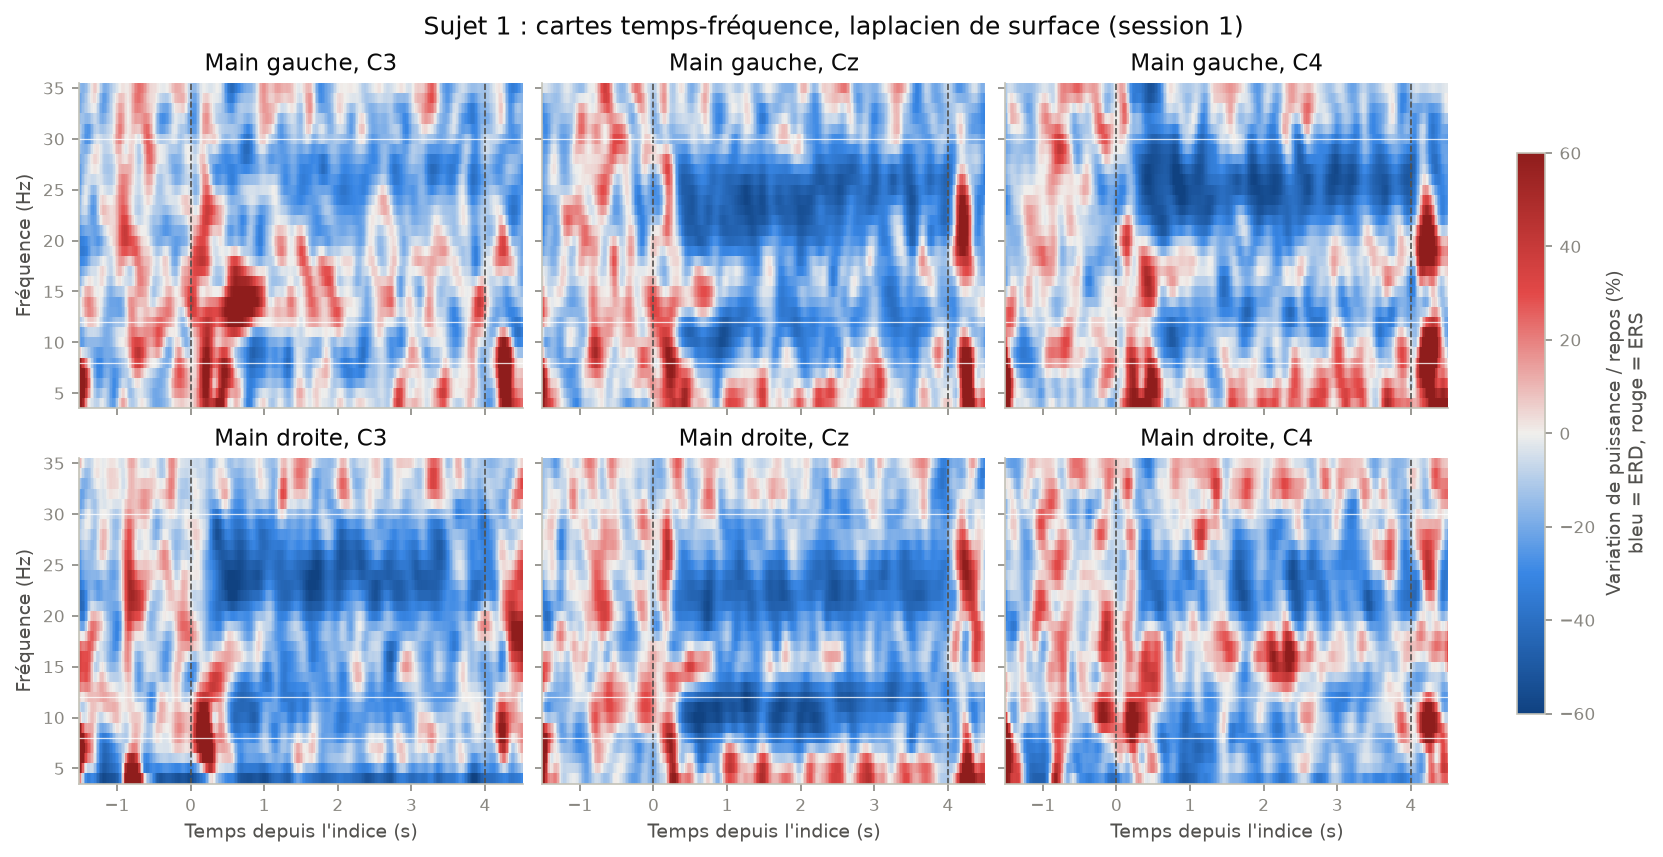

In [4]:
display(Image("reports/figures/phase1_tfr_sujet01_laplacien.png"))

## 5. Topographies de l'ERD (sujet 1)

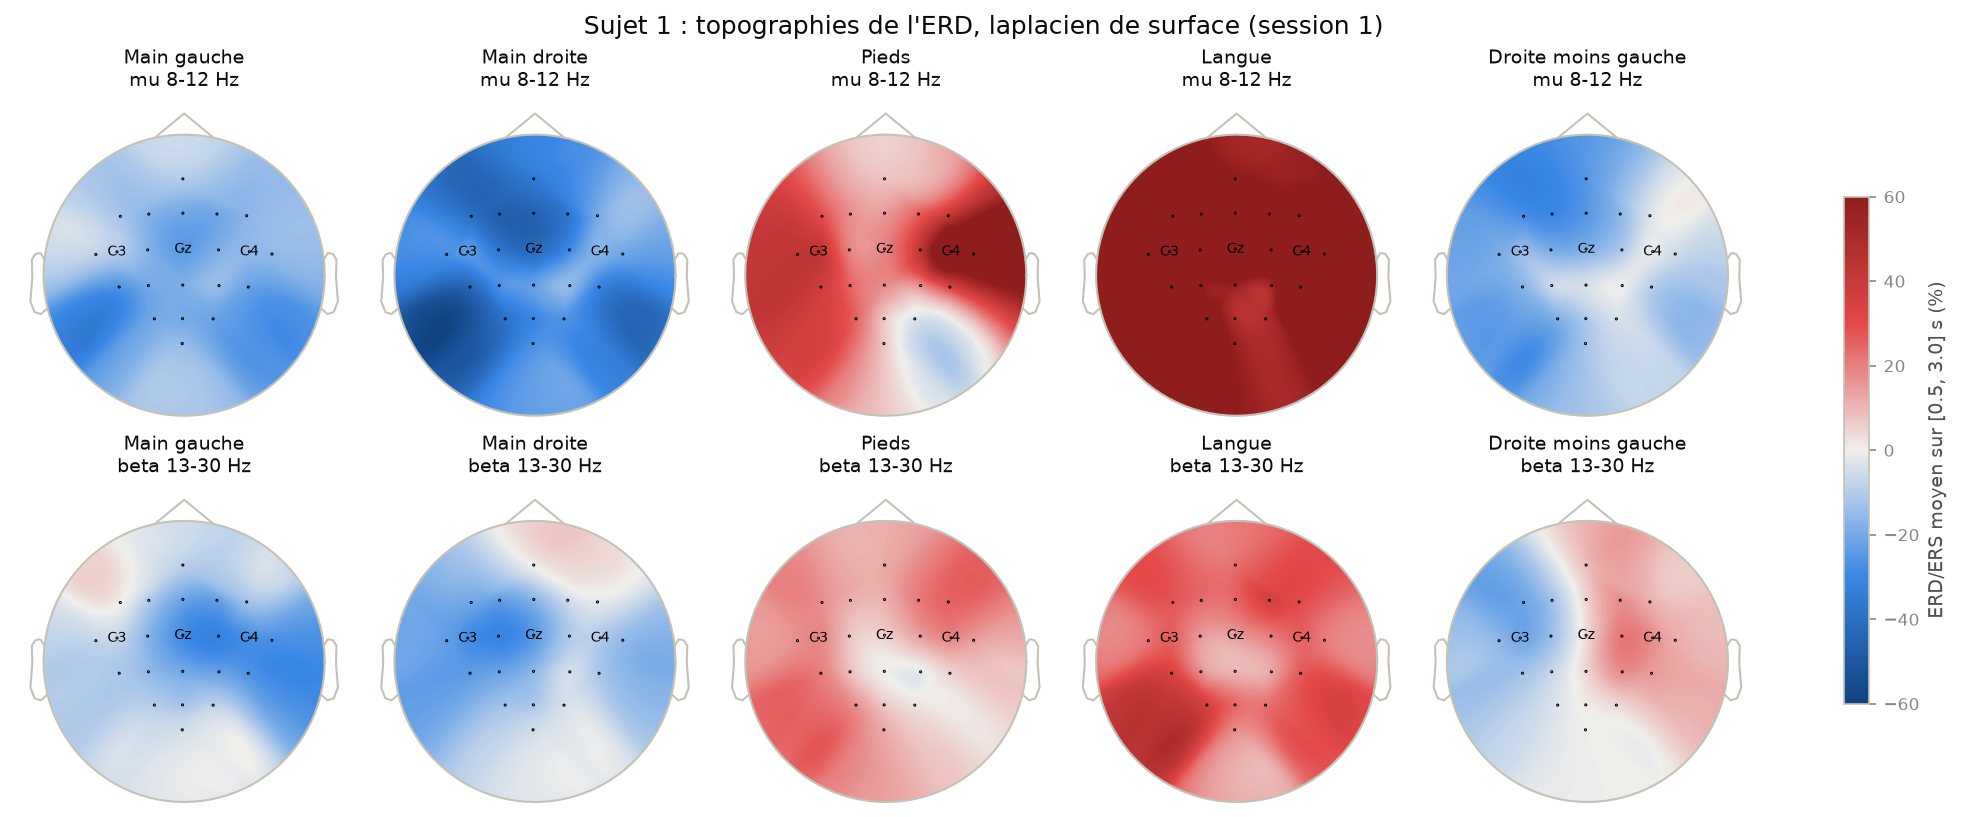

In [5]:
display(Image("reports/figures/phase1_topo_sujet01_laplacien.png"))

## 6. Moyenne des 9 sujets

Chaque sujet est d'abord normalisé par sa propre période de repos, puis les cartes d'ERD% sont moyennées.

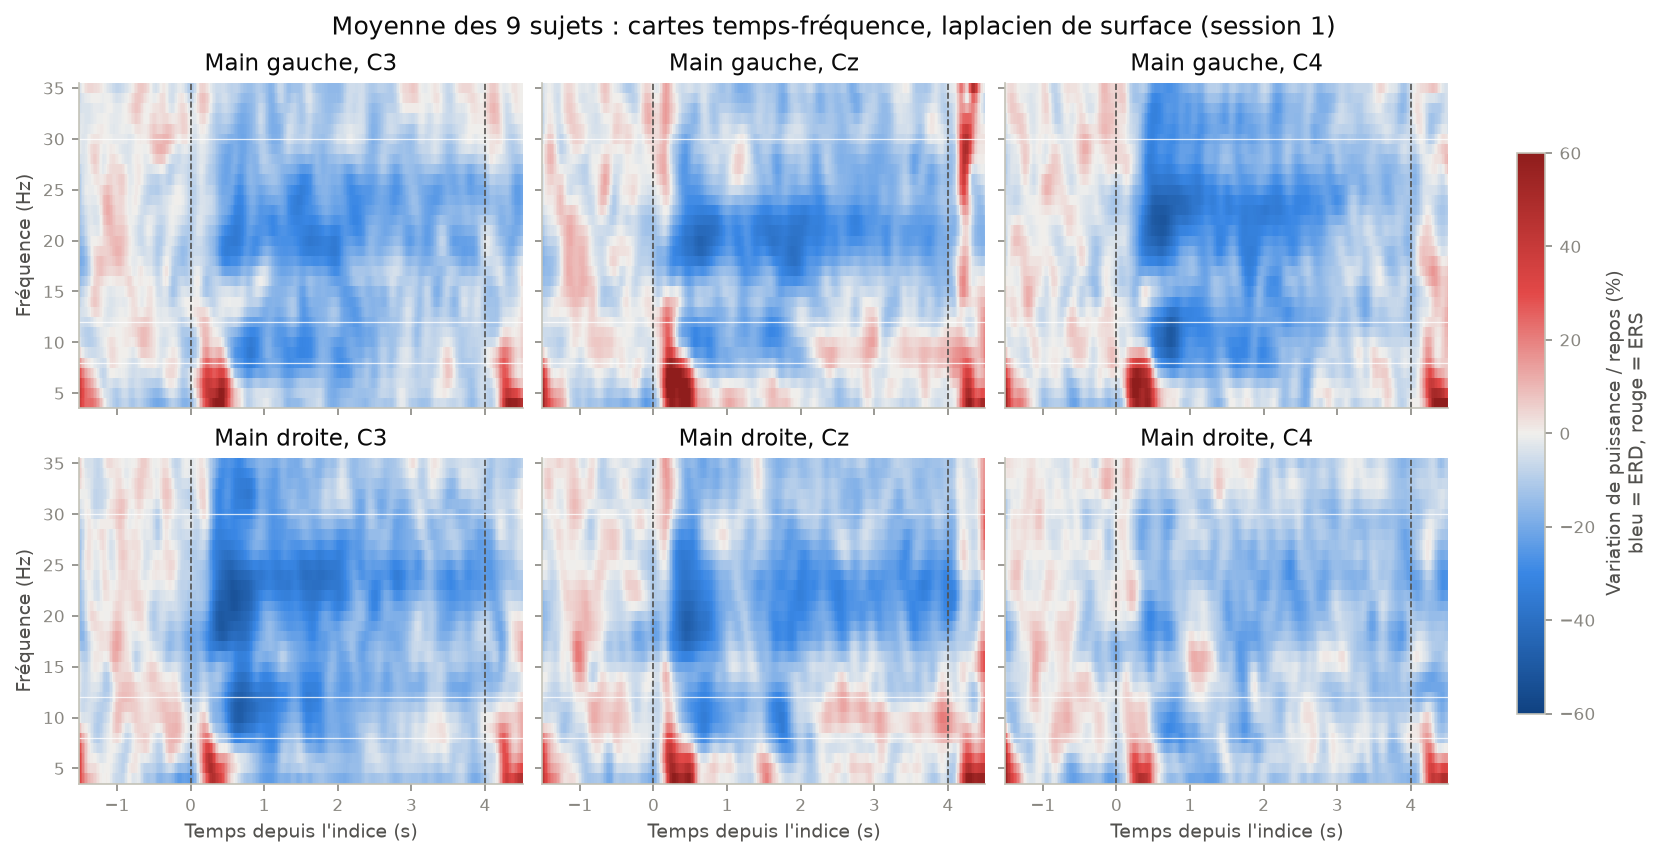

In [6]:
display(Image("reports/figures/phase1_tfr_moyenne_laplacien.png"))

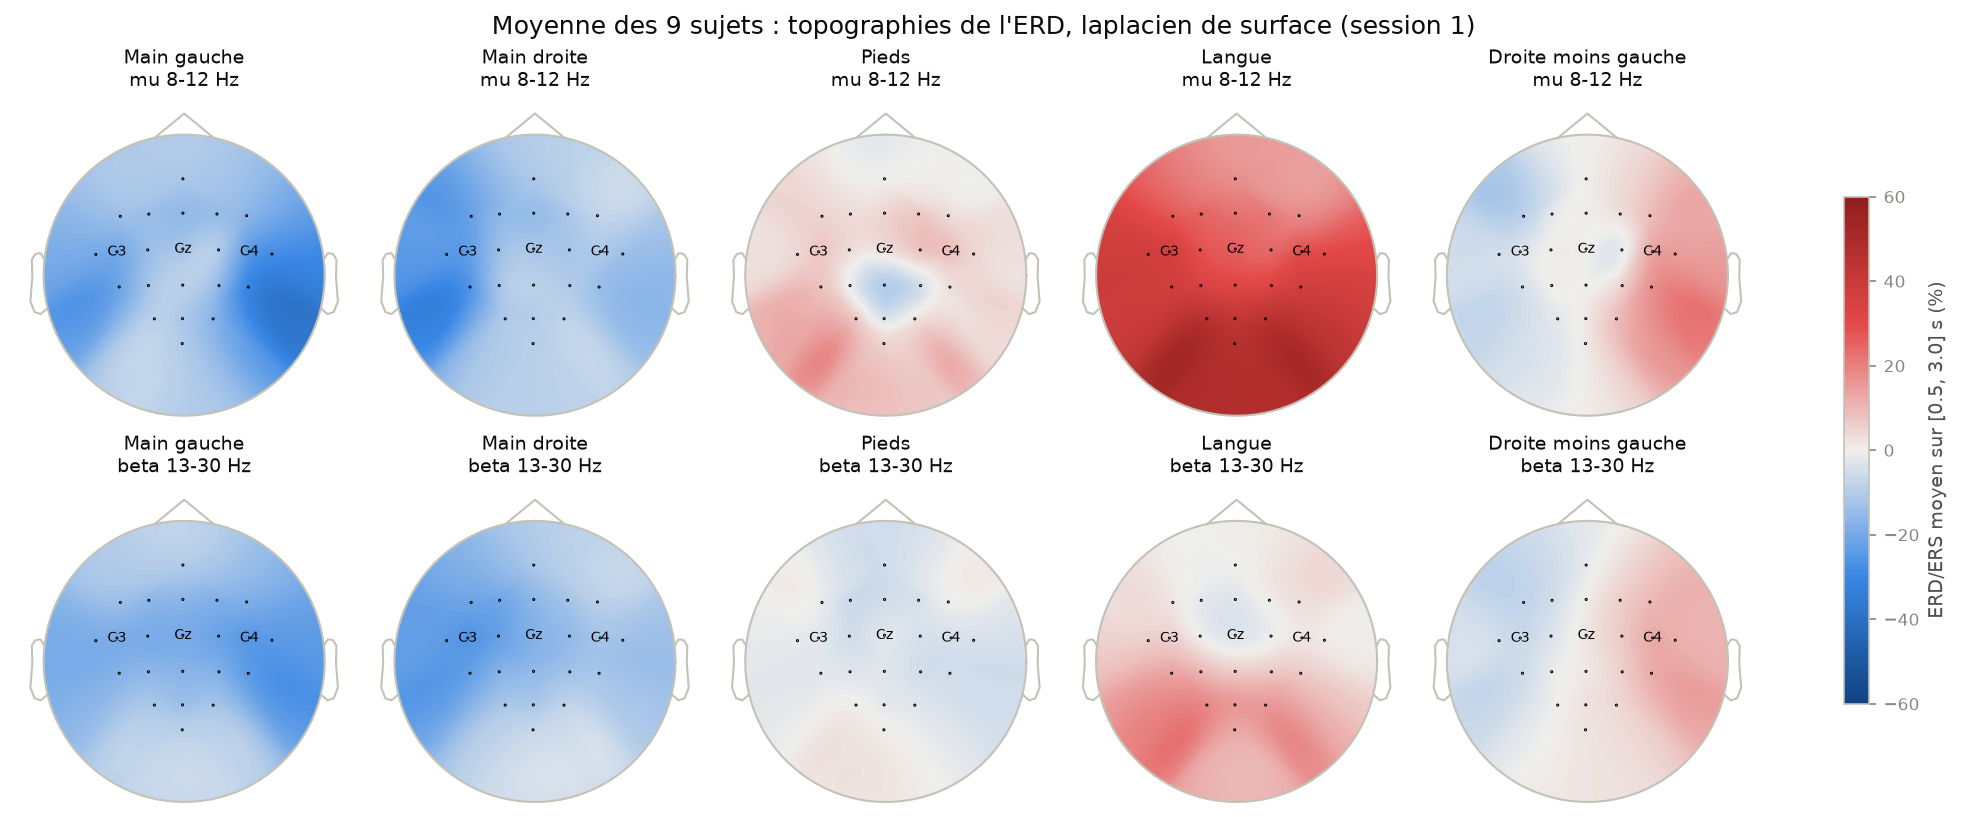

In [7]:
display(Image("reports/figures/phase1_topo_moyenne_laplacien.png"))

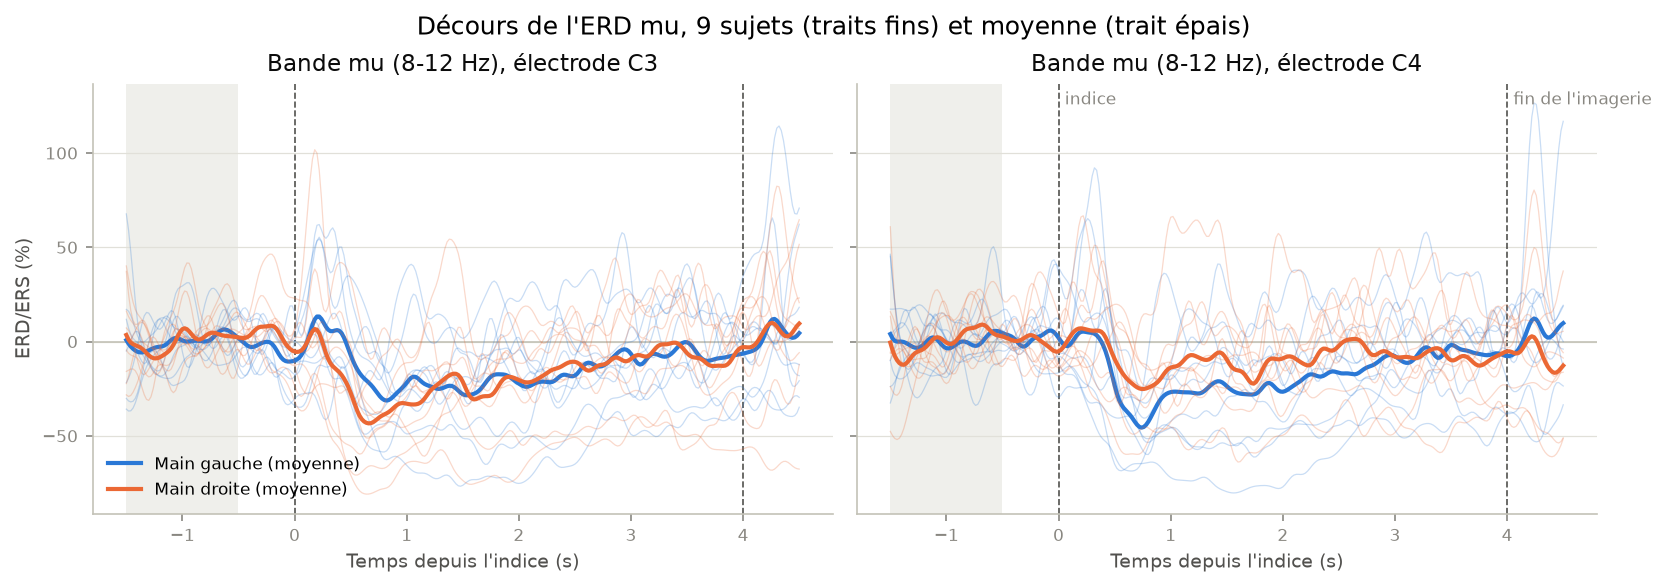

In [8]:
display(Image("reports/figures/phase1_decours_mu_c3_c4_laplacien.png"))

## 7. Latéralisation sujet par sujet, selon la dérivation

Indice = ERD controlatéral - ERD ipsilatéral (points de %). Négatif = désynchronisation plus forte
dans l'hémisphère opposé à la main imaginée, comme attendu.

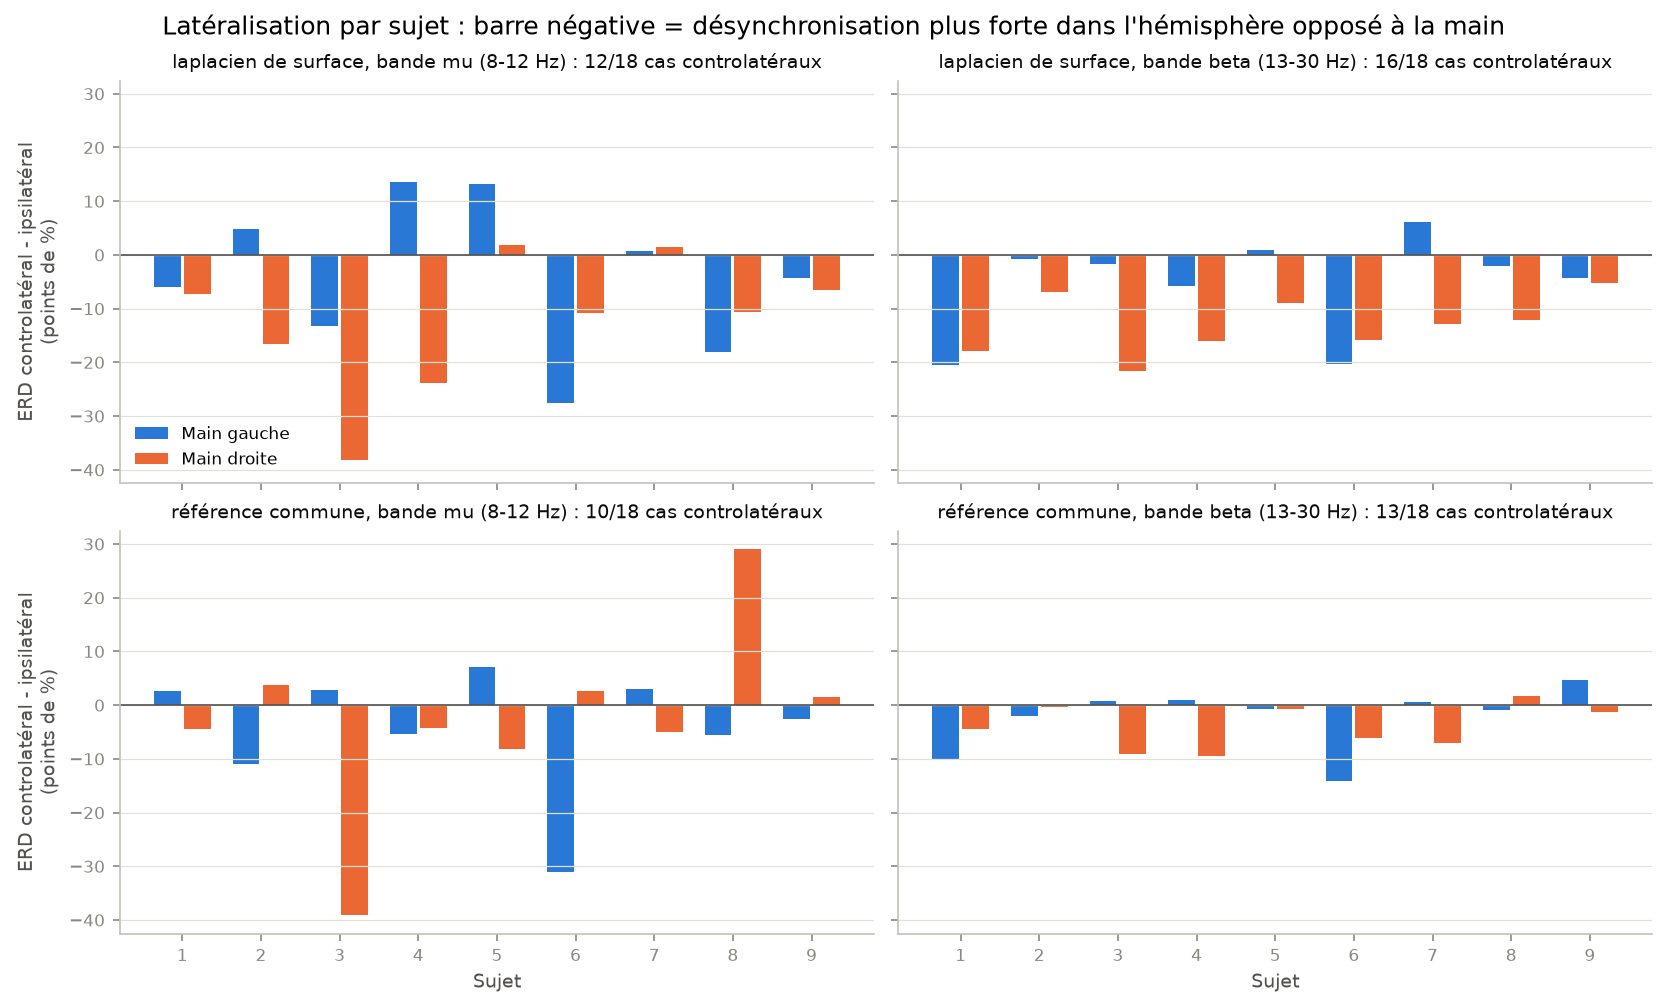

derivation laplacien                                 ref_commune             \
bande           beta                   mu                   beta              
classe     left_hand right_hand left_hand right_hand   left_hand right_hand   
sujet                                                                         
1             -20.40     -17.88     -5.96      -7.20       -9.99      -4.50   
2              -0.81      -6.95      4.89     -16.55       -2.10      -0.36   
3              -1.60     -21.66    -13.23     -38.18        0.72      -9.11   
4              -5.77     -15.97     13.57     -23.75        0.99      -9.45   
5               0.83      -8.87     13.18       1.90       -0.64      -0.67   
6             -20.31     -15.90    -27.54     -10.75      -14.10      -6.16   
7               6.13     -12.85      0.68       1.51        0.67      -6.98   
8              -2.01     -12.15    -18.08     -10.66       -0.90       1.64   
9              -4.26      -5.16     -4.38      -6.59        4.64      -1.26   

derivation                       
bande             mu             
classe     left_hand right_hand  
sujet                            
1               2.66      -4.42  
2             -10.98       3.83  
3               2.89     -39.13  
4              -5.32      -4.19  
5               7.18      -8.22  
6             -31.14       2.56  
7               3.03      -4.98  
8              -5.51      29.06  
9              -2.50       1.46

In [9]:
lat = pd.read_csv("results/phase1_lateralisation.csv")
display(Image("reports/figures/phase1_lateralisation_par_sujet.png"))
lat.pivot_table(index="sujet", columns=["derivation", "bande", "classe"], values="indice_lateralisation")

In [10]:
print("Part des cas (sujet x bande x main) avec latéralisation controlatérale :")
print(lat.groupby("derivation")["controlateral_attendu"].mean().map("{:.0%}".format).to_string())
pd.read_csv("results/phase1_lateralisation_resume.csv")

Part des cas (sujet x bande x main) avec latéralisation controlatérale :
derivation
laplacien      78%
ref_commune    64%


,derivation,bande,classe,cas_controlateraux,indice_median
0,laplacien,beta,left_hand,7,-2.01
1,laplacien,beta,right_hand,9,-12.85
2,laplacien,mu,left_hand,5,-4.38
3,laplacien,mu,right_hand,7,-10.66
4,ref_commune,beta,left_hand,5,-0.64
5,ref_commune,beta,right_hand,8,-4.50
6,ref_commune,mu,left_hand,5,-2.50
7,ref_commune,mu,right_hand,5,-4.19
